<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QNN_KnowledgeDistillationDDoS_Krishnamurthy2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum-enhanced knowledge distillation for DDoS detection: Krishnamurthy et al. (2026) step by step

This notebook rebuilds the experiment of one paper:

Bhargavi Krishnamurthy, Saikat Das and Sajjan G. Shiva, "Early Detection of Distributed Denial of Service in Cloud Computing Using Quantum-Enhanced Knowledge Distillation Framework", *Electronics* 15(11), 2327, 2026. DOI [10.3390/electronics15112327](https://doi.org/10.3390/electronics15112327).

**What the notebook does.** It downloads a slice of the CIC-DDoS2019 traffic data by itself, turns each network flow into rotation angles, trains a larger **quantum teacher** circuit and a much smaller **quantum student** circuit (Qiskit circuits, run on a simulator), and trains the student with **knowledge distillation**: the student learns from the teacher's soft probabilities, not only from the true labels. It also builds the classical CNN-LSTM teacher that the paper's Algorithm 1 uses, and compares every model with ordinary classical baselines (random forest, SVM, small neural network) on exactly the same inputs.

**How to run it.** Open it in Google Colab, keep the normal CPU runtime and choose Runtime, then Run all. No GPU and no IBM account are needed. The notebook ships with `FAST_MODE = False` and the outputs stored in it come from that full run (about 2 hours on one laptop CPU, dominated by the 8-qubit quantum teacher). Set `FAST_MODE = True` in the configuration cell for the class demo that runs in about 10 minutes with smaller budgets.

**What you get at the end.** Your own measured accuracy, precision, recall and F1 for each model, confusion matrices, a check that the student really mimics the teacher, parameter counts and timings, and a table that puts the paper's numbers next to yours. A warning up front: the paper reports its results as *cloud-simulator* metrics (packet loss rate, detection time in milliseconds, recovery ratio, bandwidth use, response time) produced with DynamicCloudSim. It never reports accuracy or F1 on the CIC-DDoS2019 flows. So most of its numbers cannot be checked with a notebook, and the final table says so claim by claim.

## 1. The paper in one page

**Problem.** In a cloud data centre a DDoS attack (many infected machines flooding a service) exhausts virtual machines, bandwidth and money. Early detection matters, but big deep-learning detectors are slow and heavy.

**Decision.** Every client request (a network flow) is labelled *normal* or *DDoS*. This is a yes/no classification.

**Method (the "QKD" framework).**
1. Pre-process CIC-DDoS2019 flows (clean, normalise, balance with SMOTE/under-sampling).
2. **Teacher.** Algorithm 1 trains a hybrid CNN + LSTM on the features and produces *soft labels* (probabilities, with temperature T). The abstract and conclusion call the teacher a *parameterised quantum circuit* (PQC). We build both and compare them.
3. **Quantum encoding.** Each feature becomes a rotation angle (`RY`), then a trainable layer of `RX/RY/RZ` rotations and a ring of `CNOT` gates, then a Pauli-Z expectation value is measured.
4. **Student.** A much smaller PQC is trained with `Total_loss = alpha * CE + (1 - alpha) * KL(teacher || student)` at temperature T, using the **parameter-shift rule** for gradients.
5. Deployment: the student classifies each arriving request; attacked requests are dropped or blocked.

**Hyper-parameters the paper gives.** learning rate 0.001, batch size 65, 50 epochs, 16 qubits, 3 circuit layers, T = 3, CNN with 33 filters (kernel 4) then 64 filters (kernel 3), dense layer of 65 neurons, 70/15/15 train/validation/test split, 5 to 10 repeated runs.

**Data.** CIC-DDoS2019: normal traffic plus SYN, UDP, LDAP, NetBIOS, DNS, MSSQL and SSDP floods.

**Claims.** All results are cloud-simulator metrics (DynamicCloudSim 3.0.3 coupled to Qiskit through a REST API): best configuration (Table 2) packet loss rate 3.9, attack detection time 118 (ms), attack recovery ratio 95.2, bandwidth utilisation 88.7, response time 139 (ms); detection about 40 ms vs 150 to 250 ms for six baselines (Figure 4); recovery 99% vs 30 to 50% (Figure 5); the ablation of Table 3 (CNN only, LSTM only, CNN-LSTM, quantum only, CNN + quantum, CNN-LSTM + quantum) with the full model best. **No accuracy, precision, recall or F1 value is reported anywhere.**

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CIC-DDoS2019, 80 CICFlowMeter features | Same dataset, public Hugging Face copy. To avoid downloading 20+ GB, only the first few MB of each attack CSV are read with HTTP range requests (`# CHOICE:` documented in the data section). SWaT (listed in our index) is not used in the paper. |
| Classes | normal + SYN, UDP, LDAP, NetBIOS, DNS, MSSQL, SSDP | Same 7 families + benign, kept as multiclass labels for plots, binary (normal / DDoS) for training |
| Balancing | SMOTE + under/over-sampling | Class-balanced down-sampling (50% benign, 50% attack spread evenly over the 7 families); no synthetic samples, so no leakage risk |
| Split | 70 / 15 / 15 train / validation / test | Same, stratified |
| Features | 7 named features, "feature size 100" for the CNN (inconsistent in the paper) | Cleaned CICFlowMeter columns (about 66). The CNN-LSTM sees the 20 selected, standardised ones. The PQCs see `SelectKBest(20)` then `StandardScaler` then `PCA`, one PCA component per qubit, scaled to angles in [0, pi]; all fitted on the training split only |
| Classical teacher | CNN (33 filters k=4, 64 filters k=3) + LSTM + dense 65 + softmax | Same layer sizes in PyTorch; LSTM hidden size 32 (`# CHOICE:`) |
| Quantum teacher | PQC, 16 to 32 qubits, 3 layers | 6 qubits / 2 layers (`FAST_MODE`) or 8 qubits / 3 layers (full run): parameter-shift training of 16 qubits is far beyond a CPU simulator (`# CHOICE:`) |
| Quantum student | "shallow" PQC, size not given | 4 qubits, 2 layers (24 weights), uses the 4 leading PCA angles (`# CHOICE:`) |
| Circuit | `RY` angle encoding, `RX/RY/RZ` rotation layer, `CNOT` entanglement, Pauli-Z readout | Same; CNOT ring `i -> i+1 mod n`; readout `<Z>` on the last qubit (`# CHOICE:`) |
| Output map | `<Z>` to 2-class softmax (not specified) | `logits = [6 Z, -6 Z]` (`# CHOICE:`, scale chosen so that probabilities can reach about 0.998) |
| Loss | `alpha * CE + (1 - alpha) * KL`, T = 3 | Same, `alpha = 0.5`, KL scaled by T^2 as in Hinton et al. (`# CHOICE:`) |
| Gradient | parameter-shift rule | Same, exact two-term shift pi/2 for every weight (vectorised numpy simulator, checked against Qiskit) |
| Optimiser | Adam, lr 0.001, batch 65, 50 epochs | Adam, batch 65. The learning rate is picked on the validation split from {0.001 (paper), 0.01, 0.05}; epochs reduced (`# CHOICE:`) |
| Hyper-parameter search | Bayesian optimisation | Not repeated (cost); only the learning-rate sweep above |
| Metrics | PLR, ADT, ARR, BU, RT from DynamicCloudSim | Not reproducible without DynamicCloudSim. We report accuracy / precision / recall / F1, inference time per flow, parameter counts and teacher-student agreement instead |

## 2. Install the libraries

Colab already has NumPy, pandas, scikit-learn, Matplotlib and PyTorch. We add Qiskit (to build and draw the circuits), `qiskit-machine-learning` (used to cross-check our gradients) and `pylatexenc` (needed to draw circuits as pictures). Versions are pinned to the ones this notebook was tested with. If Colab asks you to restart the session after this cell, accept and run the notebook again.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


## 3. Settings

Every number you may want to change is in this one cell.

* `FAST_MODE = False` (as shipped, outputs stored from this run, about 2 hours on a CPU) uses 700 flows per class, an 8-qubit / 3-layer teacher, more epochs and 3 repeated runs. `FAST_MODE = True` gives a class demo of about 10 minutes (300 flows per class, 6-qubit / 2-layer teacher, 2 runs).
* `N_T_QUBITS`, `T_LAYERS` describe the quantum **teacher**; `N_S_QUBITS`, `S_LAYERS` the **student**. The student reads only the first `N_S_QUBITS` PCA angles.
* `TEMPERATURE = 3` and `ALPHA = 0.5` are the distillation settings (the paper gives T = 3, not alpha).
* `LR_GRID` is the set of learning rates tried on the validation split (the paper's 0.001 is in it).
* The Hugging Face data are public. If you ever use a gated copy, put your own token in Colab Secrets under the name `HF_TOKEN`; it is read from the environment or Colab Secrets and never written anywhere.

In [2]:
SEED = 42
FAST_MODE = False           # True: about 10 min class demo. False: larger budgets (see below)

# ---- data -------------------------------------------------------------------------------
HF_REPO = "baalajimaestro/CICDDoS2019"          # public copy of the original CIC-DDoS2019 CSV files
DATA_DIR = "qc068_data"                         # small cache of the sampled flows (a few MB)
ATTACK_FILES = {                                 # the 7 attack families of the paper (day 01-12)
    "DrDoS_DNS": "01-12/DrDoS_DNS.csv", "DrDoS_LDAP": "01-12/DrDoS_LDAP.csv",
    "DrDoS_MSSQL": "01-12/DrDoS_MSSQL.csv", "DrDoS_NetBIOS": "01-12/DrDoS_NetBIOS.csv",
    "DrDoS_SSDP": "01-12/DrDoS_SSDP.csv", "DrDoS_UDP": "01-12/DrDoS_UDP.csv", "Syn": "01-12/Syn.csv"}
BENIGN_FILE = "01-12/DrDoS_DNS.csv"             # the DNS file contains the most benign flows (about 1,700 in 16 MB)
BYTES_ATTACK = 3_000_000                         # bytes read from the start of every attack file (about 7,000 flows)
BYTES_BENIGN = 16_000_000                        # bytes read from the start of the benign file
POOL_ATTACK_PER_FAMILY = 1500                    # flows kept per family before the final balanced sample
POOL_BENIGN = 2000
DROP_COLUMNS = ["Unnamed: 0", "Flow ID", "Source IP", "Source Port", "Destination IP", "Destination Port",
                "Timestamp", "SimillarHTTP", "Inbound"]   # identifiers + 'Inbound' (all benign flows are outbound: a shortcut)

# ---- split and encoding ---------------------------------------------------------------------
VAL_FRAC, TEST_FRAC = 0.15, 0.15                 # paper: 70 / 15 / 15
SELECT_K = 20                                    # SelectKBest features before PCA   # CHOICE
LOGIT_SCALE = 6.0                                # logits = [s Z, -s Z]                # CHOICE

# ---- distillation ---------------------------------------------------------------------------
TEMPERATURE = 3.0                                # paper
ALPHA = 0.5                                      # weight of the hard-label cross entropy   # CHOICE
BATCH = 65                                       # paper
LR_GRID = [0.001, 0.01, 0.05]                    # 0.001 is the paper's value; the best one on validation is used
CNN_LSTM_LR = 3e-3                               # paper: 0.001; raised because we train far fewer steps   # CHOICE

if FAST_MODE:
    N_PER_CLASS = 300                            # benign flows = attack flows = 300 (total 600)
    N_T_QUBITS, T_LAYERS = 6, 2                  # quantum teacher
    N_S_QUBITS, S_LAYERS = 4, 2                  # quantum student
    EPOCHS_Q, EPOCHS_C = 10, 15                  # quantum / classical epochs
    N_SEEDS = 2
    CNN_LSTM_EPOCHS = 20
else:
    N_PER_CLASS = 700
    N_T_QUBITS, T_LAYERS = 8, 3
    N_S_QUBITS, S_LAYERS = 4, 2
    EPOCHS_Q, EPOCHS_C = 20, 40
    N_SEEDS = 3
    CNN_LSTM_EPOCHS = 40

IBM_TOKEN = ""                                   # optional; real hardware is not used in this notebook
print("FAST_MODE =", FAST_MODE, "| flows per class =", N_PER_CLASS, "| teacher", (N_T_QUBITS, T_LAYERS),
      "| student", (N_S_QUBITS, S_LAYERS), "| seeds =", N_SEEDS)

FAST_MODE = False | flows per class = 700 | teacher (8, 3) | student (4, 2) | seeds = 3


In [3]:
import os, io, time, math, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.utils import algorithm_globals
import torch, torch.nn as nn, torch.nn.functional as F

warnings.filterwarnings("ignore")
torch.set_num_threads(2)

# Hugging Face token: only needed for gated copies; the public repo works without one.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def seed_everything(seed):
    np.random.seed(seed); torch.manual_seed(seed); algorithm_globals.random_seed = seed

seed_everything(SEED)
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| torch", torch.__version__, "| numpy", np.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | torch 2.14.1+cpu | numpy 2.5.4


## 4. Get the data

CIC-DDoS2019 was recorded by the Canadian Institute for Cybersecurity: normal user traffic plus many DDoS attacks against a test network. The tool CICFlowMeter cut the traffic into **flows** (one conversation between two machines) and measured about 80 numbers per flow (duration, packet counts, packet sizes, flag counts...). The `Label` column says `BENIGN` or the attack family.

The full CSV files are huge (0.6 to 9 GB each). We do not need millions of flows: quantum simulation limits us to hundreds. So the code reads only the **first few megabytes of each file** with an HTTP `Range` request, keeps complete rows, draws a random pool from them and stores that small pool in `DATA_DIR`. Nothing large is ever written to disk.

*Caveat (a `# CHOICE:` of this notebook).* The first megabytes of a file are a contiguous stretch of recording time, not a uniform sample of the whole day, and benign flows come only from the DNS-attack file's time window. A real evaluation should draw from all files.

In [4]:
from huggingface_hub import hf_hub_url

def fetch_head(path, nbytes):
    # Read the first nbytes of a remote CSV (HTTP Range), drop the cut last line, return a DataFrame.
    url = hf_hub_url(HF_REPO, path, repo_type="dataset")
    headers = {"Range": f"bytes=0-{nbytes - 1}"}
    if HF_TOKEN: headers["Authorization"] = f"Bearer {HF_TOKEN}"
    r = requests.get(url, headers=headers, timeout=600)
    r.raise_for_status()
    lines = r.content.decode("utf-8", "ignore").split("\n")[:-1]
    df = pd.read_csv(io.StringIO("\n".join(lines)), low_memory=False)
    df.columns = df.columns.str.strip()
    df["Label"] = df["Label"].astype(str).str.strip()
    return df

pool_file = os.path.join(DATA_DIR, "cicddos2019_pool.csv.gz")
t0 = time.perf_counter()
if os.path.exists(pool_file):
    pool = pd.read_csv(pool_file, low_memory=False)
    print("Loaded cached pool:", pool.shape)
else:
    parts = []
    big = fetch_head(BENIGN_FILE, BYTES_BENIGN)
    ben = big[big["Label"] == "BENIGN"]
    parts.append(ben.sample(n=min(POOL_BENIGN, len(ben)), random_state=SEED))
    print(f"benign file: {len(big):,} rows read, {len(ben):,} benign")
    del big
    for fam, path in ATTACK_FILES.items():
        d = fetch_head(path, BYTES_ATTACK)
        d = d[d["Label"] != "BENIGN"]
        parts.append(d.sample(n=min(POOL_ATTACK_PER_FAMILY, len(d)), random_state=SEED))
        print(f"{path}: {len(d):,} attack rows, labels {sorted(d['Label'].unique())}")
    pool = pd.concat(parts, ignore_index=True)
    pool.to_csv(pool_file, index=False, compression="gzip")
    print("Saved pool:", pool.shape, "->", pool_file)
print(f"data step took {time.perf_counter() - t0:.0f} s")
pool["Label"].value_counts()

Loaded cached pool: (12200, 88)
data step took 1 s


Label
BENIGN           1700
DrDoS_DNS        1500
DrDoS_LDAP       1500
DrDoS_MSSQL      1500
DrDoS_NetBIOS    1500
DrDoS_SSDP       1500
DrDoS_UDP        1500
Syn              1500
Name: count, dtype: int64

## 5. Clean the flows and draw a balanced sample

Cleaning follows the usual recipe for CICFlowMeter data: remove identifier columns (IP addresses, ports, timestamps, flow id), the `SimillarHTTP` column and `Inbound` (every benign flow in this slice is outbound and every attack flow inbound, so `Inbound` alone would solve the task), turn everything to numbers, replace infinities by missing values and drop those rows, then drop duplicate rows and constant columns.

Then we draw the **balanced** sample used in the experiments: `N_PER_CLASS` benign flows and `N_PER_CLASS` attack flows, with the attack flows spread evenly over the seven families. The paper uses SMOTE (synthetic minority samples); a balanced down-sample needs no synthetic points and cannot leak information between splits. The binary target is `0 = normal`, `1 = DDoS`; the family name is kept for the plots and for a per-family recall table.

In [5]:
df = pool.copy()
df["Label"] = df["Label"].astype(str).str.strip()
feature_cols = [c for c in df.columns if c not in DROP_COLUMNS + ["Label"]]
df[feature_cols] = df[feature_cols].apply(pd.to_numeric, errors="coerce")
n0 = len(df)
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=feature_cols)
df = df.drop_duplicates(subset=feature_cols + ["Label"])
const = [c for c in feature_cols if df[c].nunique() <= 1]
feature_cols = [c for c in feature_cols if c not in const]
print(f"rows {n0:,} -> {len(df):,} after inf/NaN and duplicates; dropped {len(const)} constant columns; {len(feature_cols)} features remain")

families = sorted(f for f in df["Label"].unique() if f != "BENIGN")
per_family = N_PER_CLASS // len(families)
parts = [df[df["Label"] == "BENIGN"].sample(n=N_PER_CLASS, random_state=SEED)]
for fam in families:
    sub = df[df["Label"] == fam]
    parts.append(sub.sample(n=min(per_family, len(sub)), random_state=SEED))
data = pd.concat(parts, ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
X_all = data[feature_cols].to_numpy(dtype=float)
fam_all = data["Label"].to_numpy()
y_all = (fam_all != "BENIGN").astype(int)

idx = np.arange(len(data))
idx_trval, idx_te = train_test_split(idx, test_size=TEST_FRAC, stratify=fam_all, random_state=SEED)
idx_tr, idx_va = train_test_split(idx_trval, test_size=VAL_FRAC / (1 - TEST_FRAC), stratify=fam_all[idx_trval], random_state=SEED)
Xtr_raw, Xva_raw, Xte_raw = X_all[idx_tr], X_all[idx_va], X_all[idx_te]
ytr, yva, yte = y_all[idx_tr], y_all[idx_va], y_all[idx_te]
ftr, fva, fte = fam_all[idx_tr], fam_all[idx_va], fam_all[idx_te]
print("train / validation / test:", len(ytr), len(yva), len(yte), "| attack share", ytr.mean().round(3), yva.mean().round(3), yte.mean().round(3))

rows 12,200 -> 6,196 after inf/NaN and duplicates; dropped 12 constant columns; 66 features remain
train / validation / test: 980 210 210 | attack share 0.5 0.5 0.5


## Dataset Exploration and Visualisation

Before any model, look at the real data. The next cells print the shape, the feature names, the original label values with their counts, plot the class distribution (both the seven attack families and the binary normal / DDoS split), and then draw a 2-D scatter plot in which **every point is a real flow coloured by its true label**. The scatter appears twice: first the raw PCA coordinates (PCA fitted on the training split only), then the same coordinates scaled to the interval [0, pi] that the quantum circuit uses as rotation angles (see Section 6 for the pre-processing pipeline).

Pool read from CIC-DDoS2019 files: (12200, 88) | balanced experiment set: (1400, 88) | features: 66

Original label values and counts in the pool:
Label
BENIGN           1700
DrDoS_DNS        1500
DrDoS_LDAP       1500
DrDoS_MSSQL      1500
DrDoS_NetBIOS    1500
DrDoS_SSDP       1500
DrDoS_UDP        1500
Syn              1500

Label counts in the balanced experiment set (train + validation + test):
BENIGN           700
DrDoS_DNS        100
DrDoS_LDAP       100
DrDoS_MSSQL      100
DrDoS_NetBIOS    100
Syn              100
DrDoS_SSDP       100
DrDoS_UDP        100

Feature names (66):
Protocol, Flow Duration, Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Total Length of Bwd Packets, Fwd Packet Length Max, Fwd Packet Length Min, Fwd Packet Length Mean, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT T

,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Flow Packets/s,Average Packet Size,Label
0,20608,2,2,1.242236e+04,1.940994e+02,76.500000,BENIGN
1,20616,2,2,1.261156e+04,1.940241e+02,73.250000,BENIGN
2,2,3,0,0.000000e+00,1.500000e+06,0.000000,BENIGN
3,50,3,0,0.000000e+00,6.000000e+04,0.000000,BENIGN
4,3,3,0,2.066667e+07,1.000000e+06,31.000000,BENIGN
5,21248,194,0,3.996988e+06,9.130271e+03,440.041237,DrDoS_DNS


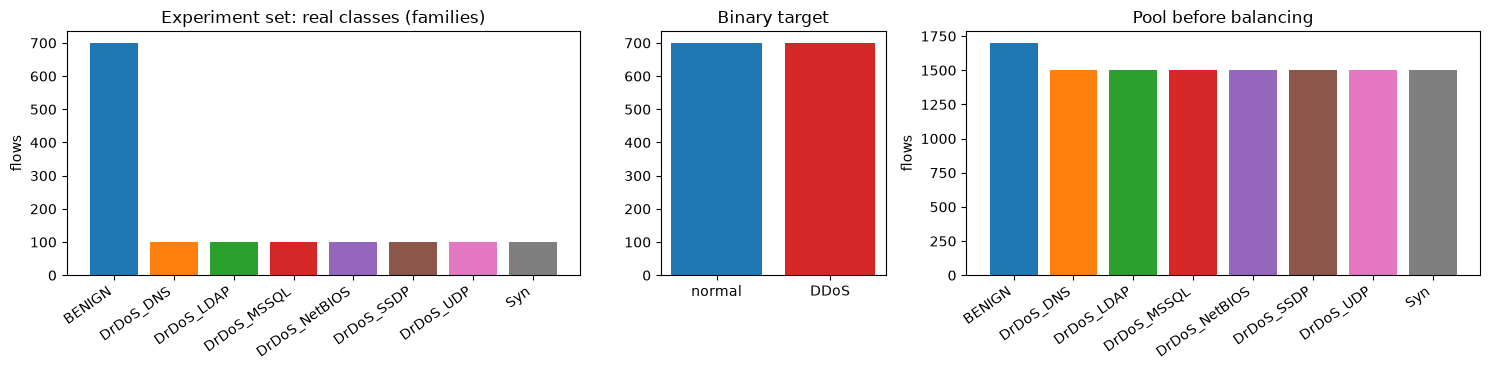

In [6]:
print("Pool read from CIC-DDoS2019 files:", pool.shape, "| balanced experiment set:", data.shape, "| features:", len(feature_cols))
print("\nOriginal label values and counts in the pool:")
print(pool["Label"].value_counts().to_string())
print("\nLabel counts in the balanced experiment set (train + validation + test):")
print(pd.Series(fam_all).value_counts().to_string())
print("\nFeature names (%d):" % len(feature_cols))
print(", ".join(feature_cols))
print("\nFirst rows (a few columns):")
display(data[["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Flow Bytes/s", "Flow Packets/s", "Average Packet Size", "Label"]].head(6))

FAM_ORDER = ["BENIGN"] + families
cmap = plt.get_cmap("tab10")
FAM_COLOR = {f: cmap(i) for i, f in enumerate(FAM_ORDER)}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.6, 0.7, 1.6]})
cnt = pd.Series(fam_all).value_counts().reindex(FAM_ORDER)
axes[0].bar(range(len(cnt)), cnt.values, color=[FAM_COLOR[f] for f in cnt.index])
axes[0].set_xticks(range(len(cnt))); axes[0].set_xticklabels(cnt.index, rotation=35, ha="right")
axes[0].set_ylabel("flows"); axes[0].set_title("Experiment set: real classes (families)")
axes[1].bar(["normal", "DDoS"], [int((y_all == 0).sum()), int((y_all == 1).sum())], color=["tab:blue", "tab:red"])
axes[1].set_title("Binary target")
cnt2 = pool["Label"].value_counts().reindex(FAM_ORDER)
axes[2].bar(range(len(cnt2)), cnt2.values, color=[FAM_COLOR[f] for f in cnt2.index])
axes[2].set_xticks(range(len(cnt2))); axes[2].set_xticklabels(cnt2.index, rotation=35, ha="right")
axes[2].set_title("Pool before balancing"); axes[2].set_ylabel("flows")
plt.tight_layout(); plt.show()

## 6. Pre-processing for the quantum circuits

A quantum circuit with `n` qubits takes `n` numbers. The CNN-LSTM teacher can read many features, but the PQCs cannot. So we build the same pipeline as the other notebooks of this repository:

`SelectKBest(f_classif, k=20)` (keep the 20 features that best separate the classes) -> `StandardScaler` -> `PCA(n_components = number of teacher qubits)` -> `MinMaxScaler((0, pi))`.

**Everything is fitted on the training split only.** Validation and test angles are clipped to [0, pi]. Each PCA component feeds one qubit. The student uses only the first `N_S_QUBITS` columns, i.e. the leading principal components, so its input is a compressed version of the teacher's input. The CNN-LSTM teacher gets the 20 selected features (standardised, no PCA) as a sequence; an extra set of baselines gets all cleaned features.

In [7]:
class AnglePipeline:
    def __init__(self, k, n_components, seed):
        self.sel = SelectKBest(f_classif, k=k); self.sc = StandardScaler()
        self.pca = PCA(n_components=n_components, random_state=seed); self.mm = MinMaxScaler((0, np.pi))
    def fit(self, X, y):
        Z = self.sel.fit_transform(X, y); Z = self.sc.fit_transform(Z); self.Zpca_train = self.pca.fit_transform(Z)
        self.mm.fit(self.Zpca_train); return self
    def pca_coords(self, X):
        return self.pca.transform(self.sc.transform(self.sel.transform(X)))
    def angles(self, X):
        return np.clip(self.mm.transform(self.pca_coords(X)), 0, np.pi)

enc = AnglePipeline(SELECT_K, N_T_QUBITS, SEED).fit(Xtr_raw, ytr)
Atr, Ava, Ate = enc.angles(Xtr_raw), enc.angles(Xva_raw), enc.angles(Xte_raw)
print("angle matrices (flows x teacher qubits):", Atr.shape, Ava.shape, Ate.shape)
print("explained variance of the PCA components:", enc.pca.explained_variance_ratio_.round(3), "sum", enc.pca.explained_variance_ratio_.sum().round(3))
print("selected features:", [str(f) for f in np.array(feature_cols)[enc.sel.get_support()]])

# The classical CNN-LSTM teacher reads the 20 selected, standardised features (before the PCA compression), as a sequence.   # CHOICE
Ftr, Fva, Fte = [np.clip(enc.sc.transform(enc.sel.transform(a)), -10, 10) for a in (Xtr_raw, Xva_raw, Xte_raw)]
# Extra classical baselines may use every cleaned feature, standardised on the training split only.
full_sc = StandardScaler().fit(Xtr_raw)
Gtr, Gva, Gte = [np.clip(full_sc.transform(a), -10, 10) for a in (Xtr_raw, Xva_raw, Xte_raw)]
print("CNN-LSTM input:", Ftr.shape, "| all-feature baseline input:", Gtr.shape)

angle matrices (flows x teacher qubits): (980, 8) (210, 8) (210, 8)
explained variance of the PCA components: [0.471 0.171 0.107 0.077 0.062 0.042 0.025 0.014] sum 0.969
selected features: ['Protocol', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s', 'Fwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'URG Flag Count', 'CWE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Subflow Fwd Bytes']
CNN-LSTM input: (980, 20) | all-feature baseline input: (980, 66)


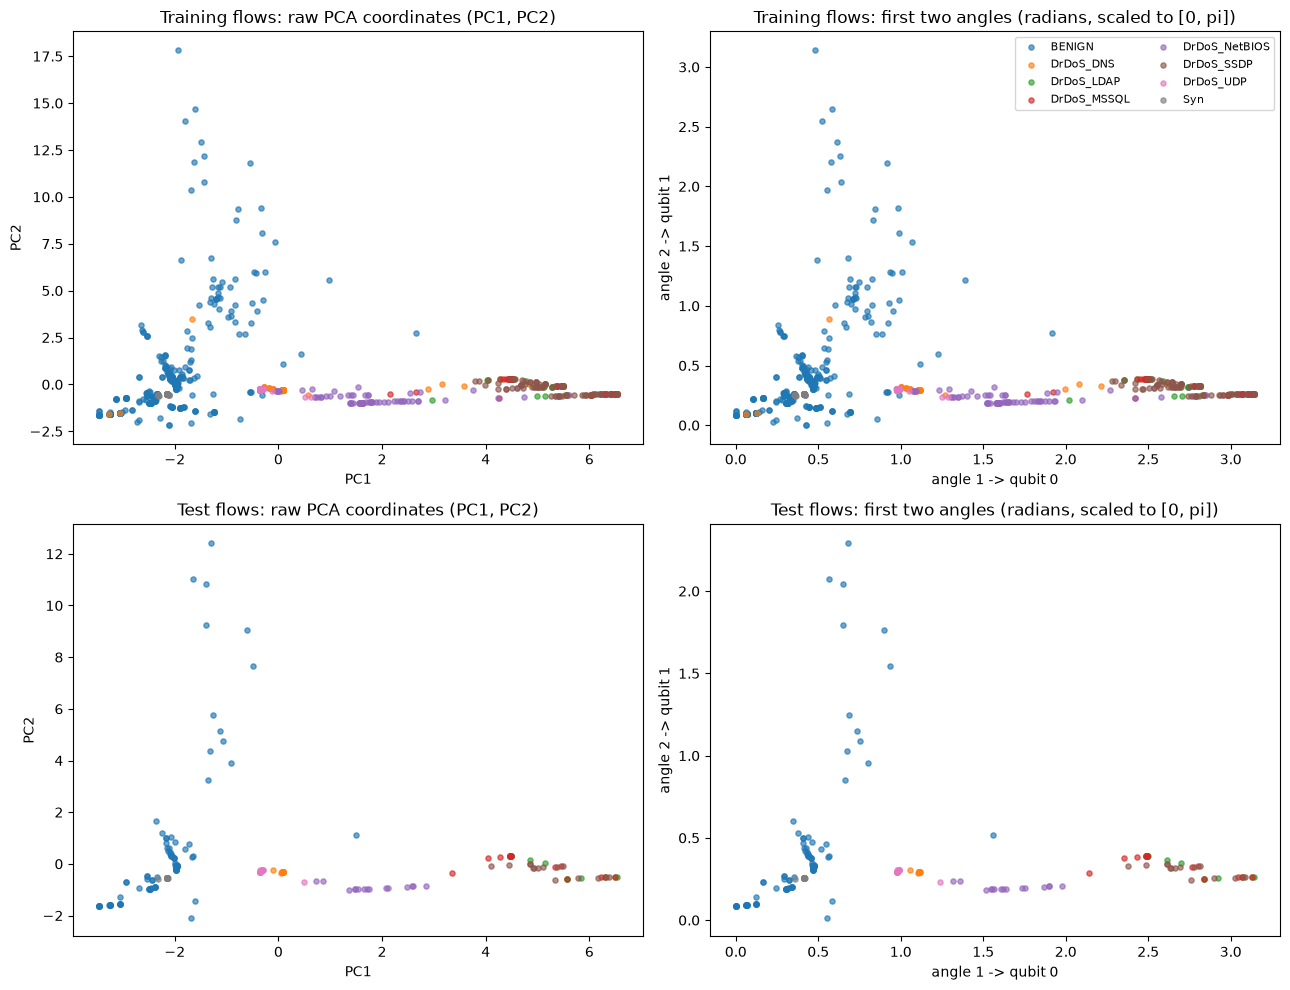

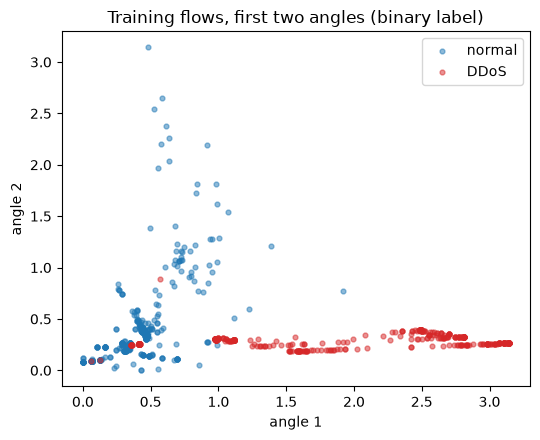

In [8]:
# Scatter 1: raw PCA coordinates (fitted on the training split). Every point is a real flow, coloured by its true family.
# Scatter 2: the same coordinates scaled to [0, pi] = the rotation angles of the first two qubits.
Ptr, Pte = enc.pca_coords(Xtr_raw), enc.pca_coords(Xte_raw)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for r, (P, A, FAMS, name) in enumerate([(Ptr, Atr, ftr, "Training flows"), (Pte, Ate, fte, "Test flows")]):
    for fam in FAM_ORDER:
        m = FAMS == fam
        axes[r, 0].scatter(P[m, 0], P[m, 1], s=14, alpha=0.65, color=FAM_COLOR[fam], label=fam)
        axes[r, 1].scatter(A[m, 0], A[m, 1], s=14, alpha=0.65, color=FAM_COLOR[fam], label=fam)
    axes[r, 0].set_title(f"{name}: raw PCA coordinates (PC1, PC2)"); axes[r, 0].set_xlabel("PC1"); axes[r, 0].set_ylabel("PC2")
    axes[r, 1].set_title(f"{name}: first two angles (radians, scaled to [0, pi])"); axes[r, 1].set_xlabel("angle 1 -> qubit 0"); axes[r, 1].set_ylabel("angle 2 -> qubit 1")
axes[0, 1].legend(loc="best", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

# Binary view of the training angles (normal vs DDoS) for the pair of angles the student uses most
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for cls, col, lab in [(0, "tab:blue", "normal"), (1, "tab:red", "DDoS")]:
    m = ytr == cls
    ax.scatter(Atr[m, 0], Atr[m, 1], s=12, alpha=0.5, color=col, label=lab)
ax.set_xlabel("angle 1"); ax.set_ylabel("angle 2"); ax.set_title("Training flows, first two angles (binary label)"); ax.legend()
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper describes the PQC in words (Algorithm 1, steps 10 and 14): *angle encoding* `U(CR) = prod_i RY(cr_i)`, a trainable block `U(theta) = prod (U_ent * U_rot(theta_l))` with a rotation layer `U_rot` (RX/RY/RZ) and an entanglement layer `U_ent` (CNOT), and a Pauli-Z expectation value as output. It gives no gate-level diagram. We therefore make the following assumptions (all marked `# CHOICE:`):

* **Encoding:** one `RY(x_i)` per qubit, the flow's i-th PCA angle in [0, pi]. (Step 10 also mentions an amplitude encoding that is "refined" by angle encoding; it is not specified well enough to implement, so only the angle encoding of step 14 is used.)
* **Rotation layer:** `RX(w) RY(w) RZ(w)` on every qubit, three trainable weights per qubit per layer.
* **Entanglement layer:** a ring of CNOTs, qubit `i` controls qubit `(i+1) mod n`.
* **Readout:** expectation of Pauli-Z on the **last** qubit; the two class logits are `[6 Z, -6 Z]`.
* **Teacher:** `N_T_QUBITS` qubits, `T_LAYERS` layers. **Student:** `N_S_QUBITS` qubits, `S_LAYERS` layer(s).

The cell below builds the two Qiskit circuits that are actually trained and evaluated in this notebook, draws them, and prints qubits, depth and the number of trainable parameters. Section 8 checks that our fast simulator reproduces these exact circuits.

TEACHER: qubits = 8, depth = 34, gates = {'ry': 32, 'rx': 24, 'rz': 24, 'cx': 24, 'barrier': 4}, trainable weights = 72, inputs = 8
STUDENT: qubits = 4, depth = 15, gates = {'ry': 12, 'rx': 8, 'rz': 8, 'cx': 8, 'barrier': 3}, trainable weights = 24, inputs = 4


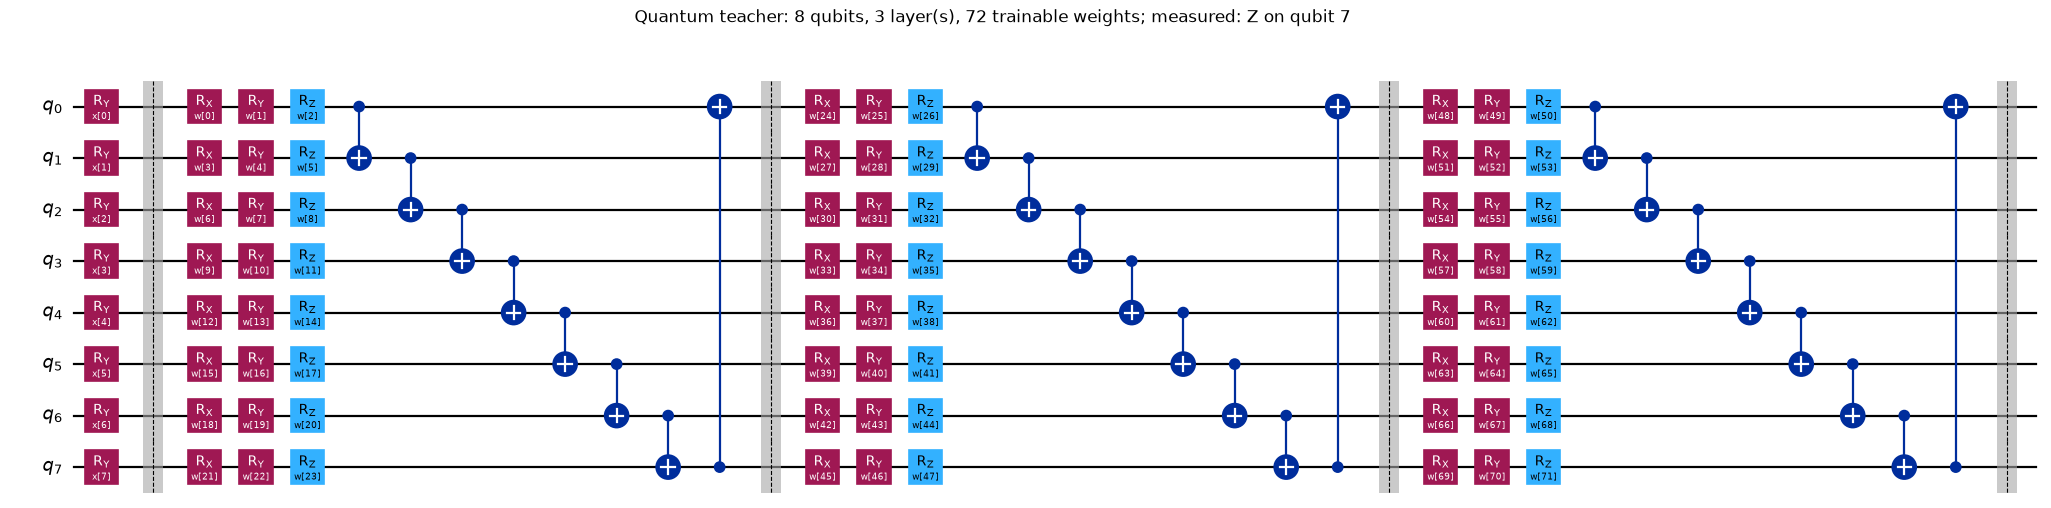

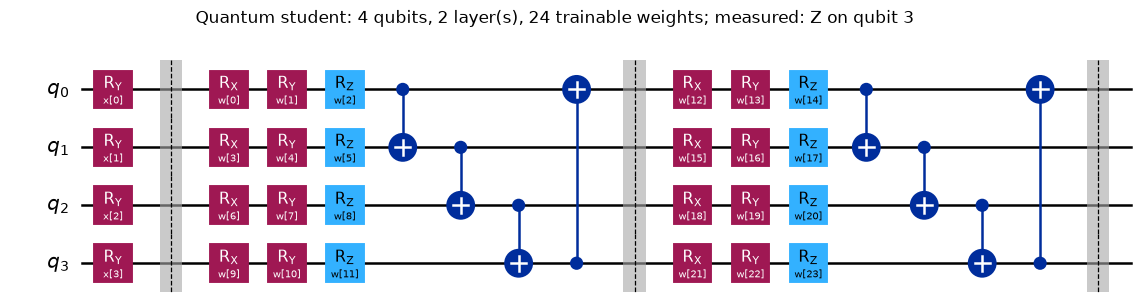

In [9]:
def build_pqc(n, layers, name):
    # CHOICE: the paper gives no gate-level diagram; this is our reading of Algorithm 1 steps 14 and 25.
    x = ParameterVector("x", n); w = ParameterVector("w", 3 * n * layers)
    qc = QuantumCircuit(n, name=name)
    for q in range(n):
        qc.ry(x[q], q)                                  # angle encoding U(CR)
    qc.barrier()
    k = 0
    for _ in range(layers):
        for q in range(n):                              # rotation layer U_rot(theta)
            qc.rx(w[k], q); qc.ry(w[k + 1], q); qc.rz(w[k + 2], q); k += 3
        for q in range(n):                              # entanglement layer U_ent: CNOT ring
            if n > 2 or q == 0:
                qc.cx(q, (q + 1) % n)
        qc.barrier()
    obs = SparsePauliOp.from_sparse_list([("Z", [n - 1], 1.0)], n)   # Pauli-Z on the last qubit
    return qc, x, w, obs

qc_T, xT, wT, obsT = build_pqc(N_T_QUBITS, T_LAYERS, "quantum_teacher")
qc_S, xS, wS, obsS = build_pqc(N_S_QUBITS, S_LAYERS, "quantum_student")
for nm, qc, w in [("TEACHER", qc_T, wT), ("STUDENT", qc_S, wS)]:
    print(f"{nm}: qubits = {qc.num_qubits}, depth = {qc.depth()}, gates = {dict(qc.count_ops())}, trainable weights = {len(w)}, inputs = {qc.num_qubits}")
fig = qc_T.draw("mpl", fold=-1, scale=0.8); fig.suptitle(f"Quantum teacher: {N_T_QUBITS} qubits, {T_LAYERS} layer(s), {len(wT)} trainable weights; measured: Z on qubit {N_T_QUBITS - 1}"); display(fig)
fig = qc_S.draw("mpl", fold=-1, scale=0.9); fig.suptitle(f"Quantum student: {N_S_QUBITS} qubits, {S_LAYERS} layer(s), {len(wS)} trainable weights; measured: Z on qubit {N_S_QUBITS - 1}"); display(fig)

## 7. A fast exact simulator for these circuits (and why we can trust it)

Training with the parameter-shift rule needs `2 x (number of weights)` circuit evaluations *per flow, per optimiser step*. Calling a Qiskit primitive that many times would take hours on a CPU. So we compile the Qiskit circuit objects above into a small vectorised **numpy state-vector simulator** that runs a whole batch of flows at once. It reads the gate list of the Qiskit circuit (`qc.data`), so it executes exactly the circuit that was drawn.

Parameter-shift rule in one sentence: for a rotation gate `R(w) = exp(-i w P / 2)`, the derivative of the expectation value is `(f(w + pi/2) - f(w - pi/2)) / 2`, exactly, so gradients come from two extra circuit runs per weight and no backpropagation through the quantum state is needed. (Quantum hardware can only do this; classical simulators could use faster tricks, but we follow the paper.)

The next cell defines the simulator; the one after proves, with assertions, that it matches Qiskit's own `Statevector` expectation values, finite differences, and the gradient that `qiskit-machine-learning` computes with its parameter-shift gradient.

In [10]:
class BatchedSim:
    # Compile a Qiskit circuit (RX/RY/RZ/CX/barrier only) into a vectorised numpy state-vector simulator.
    # State layout (batch, 2**n) with Qiskit's little-endian ordering (qubit 0 = least significant bit).
    def __init__(self, qc, x_params, w_params, obs_qubit):
        self.n = qc.num_qubits; self.obs = obs_qubit; self.dim = 2 ** self.n
        xi = {p: i for i, p in enumerate(x_params)}; wi = {p: i for i, p in enumerate(w_params)}
        basis = np.arange(self.dim); self.ops = []
        for ci in qc.data:
            nm = ci.operation.name
            if nm == "barrier": continue
            qs = [qc.find_bit(q).index for q in ci.qubits]
            if nm in ("rx", "ry", "rz"):
                p = ci.operation.params[0]
                self.ops.append((nm, qs[0], "x", xi[p]) if p in xi else (nm, qs[0], "w", wi[p]))
            elif nm == "cx":
                c, t = qs
                self.ops.append((nm, np.where((basis >> c) & 1 == 1, basis ^ (1 << t), basis), None, None))
            else:
                raise ValueError("unsupported gate " + nm)
        self.w_gate = {i: g for g, (nm, q, k, i) in enumerate(self.ops) if k == "w"}
        self.zsign = 1.0 - 2.0 * ((basis >> obs_qubit) & 1)
        self.bit = {q: (basis >> q) & 1 for q in range(self.n)}
        self.n_weights = len(w_params)
    def _init(self, B):
        st = np.zeros((B, self.dim), dtype=complex); st[:, 0] = 1.0; return st
    def _apply(self, st, op, th):
        nm, q, kind, _ = op
        if nm == "cx": return st[:, q]
        B = st.shape[0]
        if nm == "rz":
            th = np.broadcast_to(np.asarray(th, dtype=float), (B,))
            return st * np.exp(-0.5j * th[:, None] * (1 - 2 * self.bit[q][None, :]))
        v = st.reshape(B, self.dim >> (q + 1), 2, 1 << q); a0 = v[:, :, 0, :]; a1 = v[:, :, 1, :]
        th = np.asarray(th, dtype=float); c = np.cos(th / 2); s = np.sin(th / 2)
        if th.ndim: c = c.reshape(-1, 1, 1); s = s.reshape(-1, 1, 1)
        out = np.empty_like(v)
        if nm == "ry":
            out[:, :, 0, :] = c * a0 - s * a1; out[:, :, 1, :] = s * a0 + c * a1
        else:  # rx
            out[:, :, 0, :] = c * a0 - 1j * s * a1; out[:, :, 1, :] = c * a1 - 1j * s * a0
        return out.reshape(B, self.dim)
    def forward(self, X, W, start=0, state=None, shift=None, cache=None):
        st = self._init(X.shape[0]) if state is None else state
        for g in range(start, len(self.ops)):
            op = self.ops[g]
            if cache is not None: cache[g] = st
            if op[2] == "x": th = X[:, op[3]]
            elif op[2] == "w":
                th = W[op[3]] + (shift[1] if (shift is not None and shift[0] == op[3]) else 0.0)
            else: th = None
            st = self._apply(st, op, th)
        return (np.abs(st) ** 2) @ self.zsign                 # <Z_obs> for every flow in the batch
    def grad(self, X, W):
        # exact parameter-shift gradient of <Z_obs> w.r.t. every weight -> (values (B,), gradients (B, P))
        cache = {}; z = self.forward(X, W, cache=cache); G = np.zeros((X.shape[0], len(W)))
        for j, g in self.w_gate.items():
            zp = self.forward(X, W, start=g, state=cache[g], shift=(j, np.pi / 2))
            zm = self.forward(X, W, start=g, state=cache[g], shift=(j, -np.pi / 2))
            G[:, j] = 0.5 * (zp - zm)
        return z, G

simT = BatchedSim(qc_T, xT, wT, N_T_QUBITS - 1)
simS = BatchedSim(qc_S, xS, wS, N_S_QUBITS - 1)
print("compiled gate lists:", len(simT.ops), "ops (teacher),", len(simS.ops), "ops (student)")

compiled gate lists: 104 ops (teacher), 36 ops (student)


In [11]:
# Equivalence assertions: our simulator == Qiskit Statevector, == finite differences, == qiskit-machine-learning gradient.
from qiskit_machine_learning.neural_networks import EstimatorQNN
check_rng = np.random.default_rng(SEED)
for name, qc, xp, wp, obs, sim in [("teacher", qc_T, xT, wT, obsT, simT), ("student", qc_S, xS, wS, obsS, simS)]:
    n, P = qc.num_qubits, len(wp)
    Xc = check_rng.uniform(0, np.pi, (4, n)); Wc = check_rng.normal(0, 0.7, P)
    z_ours = sim.forward(Xc, Wc)
    z_qiskit = np.array([Statevector(qc.assign_parameters({**dict(zip(xp, Xc[i])), **dict(zip(wp, Wc))})).expectation_value(obs).real for i in range(len(Xc))])
    assert np.allclose(z_ours, z_qiskit, atol=1e-10), "expectation values differ from Qiskit"
    _, G = sim.grad(Xc, Wc)
    e = 1e-6; fd = np.zeros_like(G)
    for j in range(P):
        Wp, Wm = Wc.copy(), Wc.copy(); Wp[j] += e; Wm[j] -= e
        fd[:, j] = (sim.forward(Xc, Wp) - sim.forward(Xc, Wm)) / (2 * e)
    assert np.allclose(G, fd, atol=1e-6), "parameter-shift gradient differs from finite differences"
    qnn = EstimatorQNN(circuit=qc, observables=[obs], input_params=list(xp), weight_params=list(wp),
                       estimator=StatevectorEstimator(seed=SEED), default_precision=0.0, input_gradients=False)
    out = qnn.forward(Xc, Wc); _, wgrad = qnn.backward(Xc, Wc)
    assert np.allclose(out[:, 0], z_ours, atol=1e-10), "EstimatorQNN forward differs"
    assert np.allclose(wgrad[:, 0, :], G, atol=1e-8), "EstimatorQNN parameter-shift gradient differs"
    print(f"{name}: max |<Z> diff| vs Qiskit Statevector = {np.abs(z_ours - z_qiskit).max():.1e}; "
          f"max |grad diff| vs finite differences = {np.abs(G - fd).max():.1e}; vs EstimatorQNN parameter shift = {np.abs(wgrad[:, 0, :] - G).max():.1e}")
print("All equivalence assertions passed: the fast simulator runs the drawn Qiskit circuits.")

teacher: max |<Z> diff| vs Qiskit Statevector = 1.9e-16; max |grad diff| vs finite differences = 2.9e-10; vs EstimatorQNN parameter shift = 3.0e-16


student: max |<Z> diff| vs Qiskit Statevector = 1.7e-16; max |grad diff| vs finite differences = 2.2e-10; vs EstimatorQNN parameter shift = 3.1e-16
All equivalence assertions passed: the fast simulator runs the drawn Qiskit circuits.


## 8. Training with a distillation loss

For a flow with PQC output `Z` in [-1, 1] the two class logits are `[6 Z, -6 Z]` (class 0 = normal when `Z > 0`). With temperature `T` the model probabilities are `softmax(logits / T)`.

* Teacher trained on hard labels: `Loss = CE(softmax(logits), y)`.
* Student with distillation (Algorithm 1, steps 15 to 17): `Total_loss = alpha * CE(softmax(logits), y) + (1 - alpha) * T^2 * KL(P_teacher^T || P_student^T)`, where `P^T` is the softmax at temperature `T`. The `T^2` factor keeps the gradient size comparable when `T` changes (Hinton et al., 2015).
* The gradient of the loss with respect to `Z` is a small formula in the probabilities; the gradient with respect to the circuit weights then comes from the **parameter-shift** derivative of `Z`. Adam updates the weights, batch size 65.

A *soft label* is the teacher's probability vector, for example `[0.12, 0.88]`, instead of a hard `[0, 1]`. It carries the teacher's confidence, and that extra information is what distillation hopes to transfer.

In [12]:
def softmax(a, axis=-1):
    a = a - a.max(axis=axis, keepdims=True); e = np.exp(a); return e / e.sum(axis=axis, keepdims=True)

def q_logits(z): return LOGIT_SCALE * np.stack([z, -z], axis=1)

def q_predict(sim, X, W, batch=512):
    z = np.concatenate([sim.forward(X[i:i + batch], W) for i in range(0, len(X), batch)])
    return z

def kl_div(p, q, eps=1e-12): return float(np.mean(np.sum(p * (np.log(p + eps) - np.log(q + eps)), axis=1)))

def train_pqc(sim, Xtr, ytr, Xva, yva, epochs, lr, rng, teacher_soft=None, alpha=1.0, T=TEMPERATURE, batch=BATCH, tag=""):
    # Adam + parameter-shift. teacher_soft: (N, 2) teacher probabilities at temperature T (for distillation).
    P = sim.n_weights; W = rng.normal(0, 0.3, P); m = np.zeros(P); v = np.zeros(P); t = 0
    hist = {"loss": [], "val_acc": [], "val_ce": []}; onehot = np.eye(2)[ytr]
    for ep in range(epochs):
        order = rng.permutation(len(ytr)); ep_loss = []
        for i in range(0, len(order), batch):
            b = order[i:i + batch]
            z, G = sim.grad(Xtr[b], W)
            lg = q_logits(z); p1 = softmax(lg); pT = softmax(lg / T)
            dl = alpha * (p1 - onehot[b])                                   # d CE / d logits
            loss = alpha * float(-np.mean(np.log(p1[np.arange(len(b)), ytr[b]] + 1e-12)))
            if teacher_soft is not None and alpha < 1.0:
                dl = dl + (1 - alpha) * T * (pT - teacher_soft[b])          # d (T^2 KL) / d logits
                loss += (1 - alpha) * T * T * kl_div(teacher_soft[b], pT)
            dz = LOGIT_SCALE * (dl[:, 0] - dl[:, 1])
            g = (dz[:, None] * G).mean(axis=0)
            t += 1; m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
            W = W - lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
            ep_loss.append(loss)
        zv = q_predict(sim, Xva, W); pv = softmax(q_logits(zv))
        hist["loss"].append(float(np.mean(ep_loss))); hist["val_acc"].append(float((pv.argmax(1) == yva).mean()))
        hist["val_ce"].append(float(-np.mean(np.log(pv[np.arange(len(yva)), yva] + 1e-12))))
    return W, hist

def metrics(y, pred):
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0))
print("training helpers defined")

training helpers defined


### 8.1 Choosing the learning rate on the validation split

The paper's learning rate is 0.001, but it also trains 50 epochs on far more data and does not say how its quantum parts were optimised. With our small budget a tiny rate may leave the circuit under-trained. We try each value in `LR_GRID` on the **student** circuit (cheap) with hard labels, and keep the one with the lowest validation cross entropy. The test split is not touched. The chosen rate is used for every quantum model.

In [13]:
t0 = time.perf_counter(); sweep = []
Str_a, Sva_a = Atr[:, :N_S_QUBITS], Ava[:, :N_S_QUBITS]
for lr in LR_GRID:
    W_, h_ = train_pqc(simS, Str_a, ytr, Sva_a, yva, EPOCHS_Q, lr, np.random.default_rng(SEED))
    sweep.append(dict(lr=lr, val_accuracy=h_["val_acc"][-1], val_cross_entropy=h_["val_ce"][-1], train_loss=h_["loss"][-1]))
sweep = pd.DataFrame(sweep); display(sweep)
LR_Q = float(sweep.sort_values("val_cross_entropy").iloc[0]["lr"])
print(f"chosen learning rate for the quantum models: {LR_Q}  (paper: 0.001)   [{time.perf_counter() - t0:.0f} s]")

,lr,val_accuracy,val_cross_entropy,train_loss
0,0.001,0.671429,0.584372,0.561061
1,0.010,0.900000,0.189862,0.168868
2,0.050,0.909524,0.149234,0.147346


chosen learning rate for the quantum models: 0.05  (paper: 0.001)   [89 s]


## 9. The classical models: CNN-LSTM teacher, small neural student, random forest, SVM

**CNN-LSTM teacher (Algorithm 1, steps 8 and 9).** The 20 selected, standardised features are treated as a sequence of length 20 with one channel. Layers as in the paper: `Conv1d(33 filters, kernel 4) + ReLU + MaxPool(2)`, `Conv1d(64 filters, kernel 3) + ReLU`, an LSTM (hidden size 32, our choice), a dense layer of 65 neurons and a 2-class output. Cross entropy, Adam, batch 65, learning rate 0.003 (`CNN_LSTM_LR`).

**Classical student.** A 3-layer feed-forward network on the same 4 student angles, trained either on hard labels or with the same distillation loss. This shows whether distillation helps a *classical* student as well.

**Baselines on identical inputs.** `RandomForest` (100 trees, depth 20, as the paper lists for RF) and `SVC` with an RBF kernel, trained on the teacher's angles, on the student's 4 angles and on all cleaned features.

In [14]:
class CNNLSTM(nn.Module):
    def __init__(self, hidden=32):                                   # hidden=32: CHOICE (paper says "129 parameters", not reproducible)
        super().__init__()
        self.c1 = nn.Conv1d(1, 33, 4); self.c2 = nn.Conv1d(33, 64, 3)
        self.lstm = nn.LSTM(64, hidden, batch_first=True); self.fc = nn.Linear(hidden, 65); self.out = nn.Linear(65, 2)
    def forward(self, x):
        x = F.max_pool1d(F.relu(self.c1(x.unsqueeze(1))), 2); x = F.relu(self.c2(x))
        o, _ = self.lstm(x.transpose(1, 2)); return self.out(F.relu(self.fc(o[:, -1])))

class SmallMLP(nn.Module):
    def __init__(self, d): super().__init__(); self.net = nn.Sequential(nn.Linear(d, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(), nn.Linear(8, 2))
    def forward(self, x): return self.net(x)

def train_torch(model, Xtr, ytr, epochs, lr, seed, teacher_soft=None, alpha=1.0, T=TEMPERATURE, batch=BATCH):
    g = torch.Generator().manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr)
    X = torch.tensor(Xtr, dtype=torch.float32); y = torch.tensor(ytr, dtype=torch.long)
    ts = None if teacher_soft is None else torch.tensor(teacher_soft, dtype=torch.float32)
    for ep in range(epochs):
        model.train(); order = torch.randperm(len(y), generator=g)
        for i in range(0, len(y), batch):
            b = order[i:i + batch]; lg = model(X[b])
            loss = alpha * F.cross_entropy(lg, y[b])
            if ts is not None and alpha < 1.0:
                loss = loss + (1 - alpha) * T * T * F.kl_div(F.log_softmax(lg / T, 1), ts[b], reduction="batchmean")
            opt.zero_grad(); loss.backward(); opt.step()
    return model

def torch_logits(model, X):
    model.eval()
    with torch.no_grad(): return model(torch.tensor(X, dtype=torch.float32)).numpy()

n_params = lambda m: sum(p.numel() for p in m.parameters())
print("CNN-LSTM trainable parameters:", n_params(CNNLSTM()), "| classical student parameters:", n_params(SmallMLP(N_S_QUBITS)))

CNN-LSTM trainable parameters: 21386 | classical student parameters: 234


## 10. Train everything (repeated over seeds)

For each seed the loop trains: the CNN-LSTM teacher; the quantum teacher (hard labels); then **five students** that all read the same 4 angles: (a) quantum student, hard labels only; (b) quantum student distilled from the CNN-LSTM teacher (the paper's Algorithm 1); (c) quantum student distilled from the quantum teacher (the paper's abstract); (d) classical student, hard labels; (e) classical student distilled from the CNN-LSTM teacher. A seed changes the weight initialisation and the order of the mini-batches; the data split is the same for every seed. Soft labels are computed on the training split only. Random forest and SVM are deterministic and trained once.

The quantum teacher is the slow step (about 100 parameter-shift circuit runs per flow per step). Progress is printed after each seed.

In [15]:
Str_a, Sva_a, Ste_a = Atr[:, :N_S_QUBITS], Ava[:, :N_S_QUBITS], Ate[:, :N_S_QUBITS]
MODELS = ["CNN-LSTM teacher", "Quantum teacher (hard)", "Q-student (no KD)", "Q-student KD<-CNN-LSTM", "Q-student KD<-Q-teacher",
          "Classical student (no KD)", "Classical student KD<-CNN-LSTM"]
runs = []; artefacts = {}
t_all = time.perf_counter()
for k in range(N_SEEDS):
    seed = SEED + k; seed_everything(seed); rng = np.random.default_rng(seed); t_seed = time.perf_counter(); rec = {}
    # classical teacher
    cnn = train_torch(CNNLSTM(), Ftr, ytr, CNN_LSTM_EPOCHS, CNN_LSTM_LR, seed)
    lg_cnn_tr, lg_cnn_te = torch_logits(cnn, Ftr), torch_logits(cnn, Fte)
    soft_cnn = softmax(lg_cnn_tr / TEMPERATURE)
    rec["CNN-LSTM teacher"] = dict(proba=softmax(lg_cnn_te), proba_T=softmax(lg_cnn_te / TEMPERATURE))
    # quantum teacher
    t1 = time.perf_counter()
    W_T, h_T = train_pqc(simT, Atr, ytr, Ava, yva, EPOCHS_Q, LR_Q, rng)
    zT_tr, zT_te = q_predict(simT, Atr, W_T), q_predict(simT, Ate, W_T); soft_qt = softmax(q_logits(zT_tr) / TEMPERATURE)
    rec["Quantum teacher (hard)"] = dict(proba=softmax(q_logits(zT_te)), proba_T=softmax(q_logits(zT_te) / TEMPERATURE), W=W_T, hist=h_T)
    t_teacher = time.perf_counter() - t1
    # quantum students
    for name, soft, alpha in [("Q-student (no KD)", None, 1.0), ("Q-student KD<-CNN-LSTM", soft_cnn, ALPHA), ("Q-student KD<-Q-teacher", soft_qt, ALPHA)]:
        W_S, h_S = train_pqc(simS, Str_a, ytr, Sva_a, yva, EPOCHS_Q, LR_Q, np.random.default_rng(seed + 1000), teacher_soft=soft, alpha=alpha)
        zS_te = q_predict(simS, Ste_a, W_S)
        rec[name] = dict(proba=softmax(q_logits(zS_te)), proba_T=softmax(q_logits(zS_te) / TEMPERATURE), W=W_S, hist=h_S)
    # classical students
    for name, soft, alpha in [("Classical student (no KD)", None, 1.0), ("Classical student KD<-CNN-LSTM", soft_cnn, ALPHA)]:
        mdl = train_torch(SmallMLP(N_S_QUBITS), Str_a, ytr, EPOCHS_C, 5e-3, seed, teacher_soft=soft, alpha=alpha)
        lg = torch_logits(mdl, Ste_a); rec[name] = dict(proba=softmax(lg), proba_T=softmax(lg / TEMPERATURE))
    runs.append(rec)
    print(f"seed {seed}: done in {time.perf_counter() - t_seed:.0f} s (quantum teacher {t_teacher:.0f} s) | "
          + " | ".join(f"{n.split(' (')[0]}: {(rec[n]['proba'].argmax(1) == yte).mean():.3f}" for n in MODELS))
    if k == 0: artefacts = dict(cnn=cnn, W_T=W_T, W_S=rec["Q-student KD<-Q-teacher"]["W"], W_S_cnn=rec["Q-student KD<-CNN-LSTM"]["W"])
print(f"total training time {time.perf_counter() - t_all:.0f} s")

seed 42: done in 1897 s (quantum teacher 1748 s) | CNN-LSTM teacher: 0.995 | Quantum teacher: 0.967 | Q-student: 0.910 | Q-student KD<-CNN-LSTM: 0.919 | Q-student KD<-Q-teacher: 0.910 | Classical student: 0.990 | Classical student KD<-CNN-LSTM: 0.981


seed 43: done in 1879 s (quantum teacher 1704 s) | CNN-LSTM teacher: 0.995 | Quantum teacher: 0.967 | Q-student: 0.981 | Q-student KD<-CNN-LSTM: 0.924 | Q-student KD<-Q-teacher: 0.914 | Classical student: 0.995 | Classical student KD<-CNN-LSTM: 0.995


seed 44: done in 2828 s (quantum teacher 2515 s) | CNN-LSTM teacher: 0.995 | Quantum teacher: 0.967 | Q-student: 0.919 | Q-student KD<-CNN-LSTM: 0.919 | Q-student KD<-Q-teacher: 0.914 | Classical student: 0.995 | Classical student KD<-CNN-LSTM: 0.990
total training time 6604 s


### 10.1 Training curves

Loss and validation accuracy per epoch for the quantum models of the first seed. Distillation losses include the KL term, so their absolute value is not comparable with the pure cross entropy of the teacher; look at the validation accuracy instead.

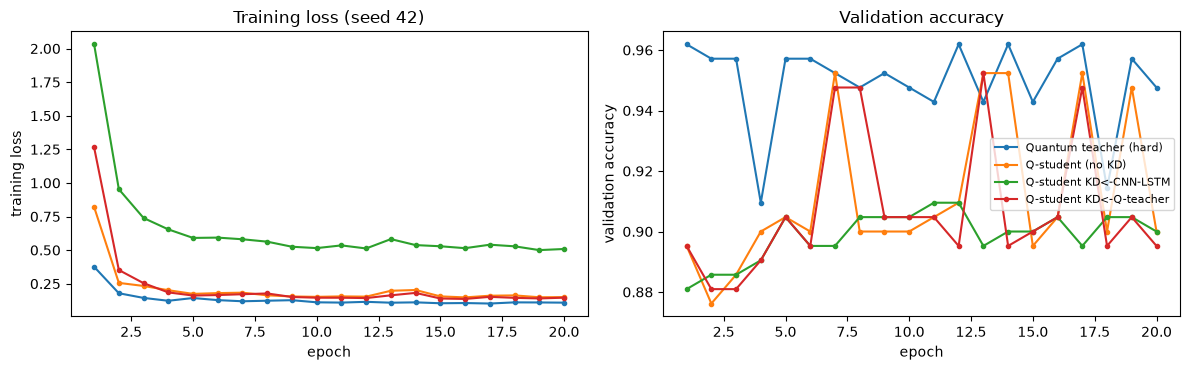

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name in ["Quantum teacher (hard)", "Q-student (no KD)", "Q-student KD<-CNN-LSTM", "Q-student KD<-Q-teacher"]:
    h = runs[0][name]["hist"]
    axes[0].plot(range(1, len(h["loss"]) + 1), h["loss"], marker="o", ms=3, label=name)
    axes[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], marker="o", ms=3, label=name)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_title("Training loss (seed %d)" % SEED)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy"); axes[1].set_title("Validation accuracy"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 11. Test-set results

Metrics are computed on the 15% test split with *DDoS = positive class*. Quantum and neural models are averaged over seeds (mean +/- std). Random forest and SVM are deterministic. The table also lists the number of trainable parameters and the number of input features each model uses.

In [17]:
rows = []
def add_row(name, preds_list, params, inputs, extra=None):
    ms = [metrics(yte, p) for p in preds_list]
    r = {"model": name, "inputs": inputs, "parameters": params}
    for key in ["accuracy", "precision", "recall", "f1"]:
        vals = np.array([m[key] for m in ms]); r[key] = f"{vals.mean():.4f} +/- {vals.std():.4f}" if len(vals) > 1 else f"{vals[0]:.4f}"
        r[key + "_mean"] = vals.mean()
    rows.append(r)

nparams = {"CNN-LSTM teacher": n_params(CNNLSTM()), "Quantum teacher (hard)": len(wT), "Q-student (no KD)": len(wS), "Q-student KD<-CNN-LSTM": len(wS),
           "Q-student KD<-Q-teacher": len(wS), "Classical student (no KD)": n_params(SmallMLP(N_S_QUBITS)), "Classical student KD<-CNN-LSTM": n_params(SmallMLP(N_S_QUBITS))}
ninp = {"CNN-LSTM teacher": f"{Ftr.shape[1]} selected features", "Quantum teacher (hard)": f"{N_T_QUBITS} angles"}
for n in MODELS:
    add_row(n, [r[n]["proba"].argmax(1) for r in runs], nparams[n], ninp.get(n, f"{N_S_QUBITS} angles"))

# deterministic classical baselines on identical inputs
rf_kw = dict(n_estimators=100, max_depth=20, criterion="gini", min_samples_split=2, min_samples_leaf=1, bootstrap=True, random_state=SEED, n_jobs=1)
base = {}
for label, (A_tr, A_te) in {f"{N_T_QUBITS} angles": (Atr, Ate), f"{N_S_QUBITS} angles": (Str_a, Ste_a), "all features": (Gtr, Gte)}.items():
    rf = RandomForestClassifier(**rf_kw).fit(A_tr, ytr); sv = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(A_tr, ytr)
    base[f"RandomForest ({label})"] = rf.predict(A_te); base[f"SVC-rbf ({label})"] = sv.predict(A_te)
    add_row(f"RandomForest ({label})", [rf.predict(A_te)], "100 trees", label); add_row(f"SVC-rbf ({label})", [sv.predict(A_te)], f"{len(sv.support_)} support vectors", label)
res = pd.DataFrame(rows).set_index("model")
display(res[["inputs", "parameters", "accuracy", "precision", "recall", "f1"]])

,inputs,parameters,accuracy,precision,recall,f1
model,,,,,,
CNN-LSTM teacher,20 selected features,21386,0.9952 +/- 0.0000,0.9906 +/- 0.0000,1.0000 +/- 0.0000,0.9953 +/- 0.0000
Quantum teacher (hard),8 angles,72,0.9667 +/- 0.0000,0.9428 +/- 0.0037,0.9937 +/- 0.0045,0.9675 +/- 0.0001
Q-student (no KD),4 angles,24,0.9365 +/- 0.0317,0.9761 +/- 0.0092,0.8952 +/- 0.0673,0.9325 +/- 0.0346
Q-student KD<-CNN-LSTM,4 angles,24,0.9206 +/- 0.0022,0.9926 +/- 0.0052,0.8476 +/- 0.0000,0.9144 +/- 0.0022
Q-student KD<-Q-teacher,4 angles,24,0.9127 +/- 0.0022,0.9745 +/- 0.0050,0.8476 +/- 0.0000,0.9066 +/- 0.0022
Classical student (no KD),4 angles,234,0.9937 +/- 0.0022,0.9875 +/- 0.0044,1.0000 +/- 0.0000,0.9937 +/- 0.0022
Classical student KD<-CNN-LSTM,4 angles,234,0.9889 +/- 0.0059,0.9843 +/- 0.0087,0.9937 +/- 0.0045,0.9890 +/- 0.0059
RandomForest (8 angles),8 angles,100 trees,0.9952,1.0000,0.9905,0.9952
SVC-rbf (8 angles),8 angles,128 support vectors,0.9714,0.9459,1.0000,0.9722


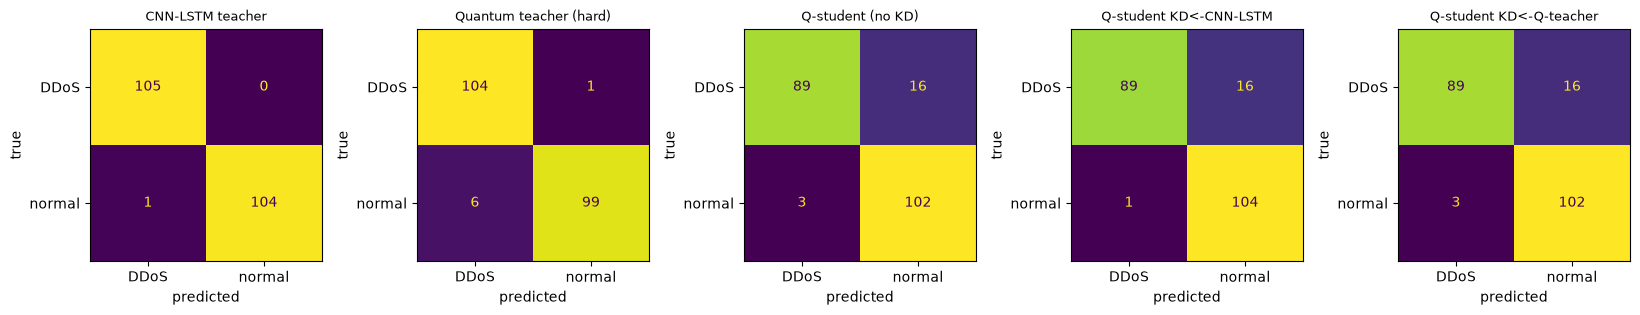

Share of test flows classified correctly, per true family (first seed):


,CNN-LSTM teacher,Quantum teacher (hard),Q-student (no KD),Q-student KD<-CNN-LSTM,Q-student KD<-Q-teacher
BENIGN,0.99,0.943,0.971,0.990,0.971
DrDoS_DNS,1.00,1.000,0.933,0.933,0.933
DrDoS_LDAP,1.00,1.000,1.000,1.000,1.000
DrDoS_MSSQL,1.00,1.000,1.000,1.000,1.000
DrDoS_NetBIOS,1.00,1.000,1.000,1.000,1.000
DrDoS_SSDP,1.00,1.000,1.000,1.000,1.000
DrDoS_UDP,1.00,1.000,1.000,1.000,1.000
Syn,1.00,0.933,0.000,0.000,0.000


In [18]:
# Confusion matrices (attack = positive class) for the first seed and the key models, plus per-family recall of the students
show = ["CNN-LSTM teacher", "Quantum teacher (hard)", "Q-student (no KD)", "Q-student KD<-CNN-LSTM", "Q-student KD<-Q-teacher"]
fig, axes = plt.subplots(1, len(show), figsize=(3.3 * len(show), 3.4))
for ax, n in zip(axes, show):
    pred = runs[0][n]["proba"].argmax(1)
    ConfusionMatrixDisplay(confusion_matrix(yte, pred, labels=[1, 0]), display_labels=["DDoS", "normal"]).plot(ax=ax, colorbar=False)
    ax.set_title(n, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

fam_rows = {}
for n in show:
    pred = runs[0][n]["proba"].argmax(1)
    fam_rows[n] = {f: float((pred[fte == f] == (0 if f == "BENIGN" else 1)).mean()) for f in FAM_ORDER}
print("Share of test flows classified correctly, per true family (first seed):")
display(pd.DataFrame(fam_rows).round(3))

## 12. Does the student mimic the teacher?

The paper's central claim is that the lightweight student "exactly" reproduces the teacher. We measure it on test flows: (i) **agreement**, the share of flows on which student and teacher predict the same class; (ii) the **KL divergence** between the teacher's and the student's temperature-3 probabilities (smaller = closer). We also compare a student trained without distillation, to see whether distillation makes the student closer to the teacher or merely closer to the true labels.

In [19]:
pairs = [("Q-student (no KD)", "Quantum teacher (hard)"), ("Q-student KD<-Q-teacher", "Quantum teacher (hard)"),
         ("Q-student (no KD)", "CNN-LSTM teacher"), ("Q-student KD<-CNN-LSTM", "CNN-LSTM teacher"),
         ("Classical student (no KD)", "CNN-LSTM teacher"), ("Classical student KD<-CNN-LSTM", "CNN-LSTM teacher")]
mim = []
for s_, t_ in pairs:
    ag = [float((r[s_]["proba"].argmax(1) == r[t_]["proba"].argmax(1)).mean()) for r in runs]
    kl = [kl_div(r[t_]["proba_T"], r[s_]["proba_T"]) for r in runs]
    mim.append({"student": s_, "teacher": t_, "agreement": f"{np.mean(ag):.4f} +/- {np.std(ag):.4f}", "KL(teacher||student) at T=3": f"{np.mean(kl):.4f} +/- {np.std(kl):.4f}",
                "agreement_mean": np.mean(ag), "kl_mean": np.mean(kl)})
mim = pd.DataFrame(mim); display(mim[["student", "teacher", "agreement", "KL(teacher||student) at T=3"]])

,student,teacher,agreement,KL(teacher||student) at T=3
0,Q-student (no KD),Quantum teacher (hard),0.9286 +/- 0.0406,0.0263 +/- 0.0059
1,Q-student KD<-Q-teacher,Quantum teacher (hard),0.9048 +/- 0.0039,0.0151 +/- 0.0026
2,Q-student (no KD),CNN-LSTM teacher,0.9349 +/- 0.0361,0.1440 +/- 0.0162
3,Q-student KD<-CNN-LSTM,CNN-LSTM teacher,0.9159 +/- 0.0022,0.0975 +/- 0.0108
4,Classical student (no KD),CNN-LSTM teacher,0.9984 +/- 0.0022,0.0560 +/- 0.0082
5,Classical student KD<-CNN-LSTM,CNN-LSTM teacher,0.9937 +/- 0.0059,0.0395 +/- 0.0309


## 13. Run the trained circuits through Qiskit itself

All training used the numpy simulator. To close the loop, the cell below takes the trained teacher and student weights of the first seed, evaluates **all test flows** through Qiskit's own `EstimatorQNN` (a `StatevectorEstimator` underneath) and checks that the predictions are the same. This is also how a real deployment would call the circuits.

In [20]:
def qiskit_predict(qc, xp, wp, obs, X, W):
    qnn = EstimatorQNN(circuit=qc, observables=[obs], input_params=list(xp), weight_params=list(wp),
                       estimator=StatevectorEstimator(seed=SEED), default_precision=0.0, input_gradients=False)
    t = time.perf_counter(); z = qnn.forward(X, W)[:, 0]; return z, (time.perf_counter() - t)

zT_q, tT = qiskit_predict(qc_T, xT, wT, obsT, Ate, artefacts["W_T"])
zS_q, tS = qiskit_predict(qc_S, xS, wS, obsS, Ste_a, artefacts["W_S"])
zT_n, zS_n = q_predict(simT, Ate, artefacts["W_T"]), q_predict(simS, Ste_a, artefacts["W_S"])
print(f"teacher: max |Z diff| {np.abs(zT_q - zT_n).max():.1e}, identical predictions: {np.array_equal(zT_q < 0, zT_n < 0)}, test accuracy via Qiskit {((zT_q < 0).astype(int) == yte).mean():.4f}")
print(f"student: max |Z diff| {np.abs(zS_q - zS_n).max():.1e}, identical predictions: {np.array_equal(zS_q < 0, zS_n < 0)}, test accuracy via Qiskit {((zS_q < 0).astype(int) == yte).mean():.4f}")
assert np.allclose(zT_q, zT_n, atol=1e-8) and np.allclose(zS_q, zS_n, atol=1e-8)

teacher: max |Z diff| 7.8e-16, identical predictions: True, test accuracy via Qiskit 0.9667
student: max |Z diff| 5.0e-16, identical predictions: True, test accuracy via Qiskit 0.9095


## 14. Is the student lighter and faster? (parameters, depth, time per flow)

The paper's second claim is efficiency: a shallow student with few qubits and gates is faster and smaller than the teacher. Wall-clock times below are those of **simulators on this CPU**, not of quantum hardware, and the cloud-simulator times in the paper (tens to hundreds of milliseconds) are a different quantity. We still measure them because they show the cost *ratio* between teacher and student circuits.

In [21]:
def per_flow_us(fn, X, reps=5):
    fn(X)                                                        # warm-up
    t = time.perf_counter()
    for _ in range(reps): fn(X)
    return (time.perf_counter() - t) / reps / len(X) * 1e6

W_T0, W_S0 = artefacts["W_T"], artefacts["W_S"]
cnn0 = artefacts["cnn"]
rf_all = RandomForestClassifier(**rf_kw).fit(Gtr, ytr); svc_s = SVC(kernel="rbf", gamma="scale").fit(Str_a, ytr)
eff = pd.DataFrame([
    {"model": "Quantum teacher", "qubits": N_T_QUBITS, "circuit depth": qc_T.depth(), "gates": sum(qc_T.count_ops().values()) - qc_T.count_ops().get("barrier", 0), "parameters": len(wT), "us per flow": per_flow_us(lambda X: q_predict(simT, X, W_T0), Ate)},
    {"model": "Quantum student", "qubits": N_S_QUBITS, "circuit depth": qc_S.depth(), "gates": sum(qc_S.count_ops().values()) - qc_S.count_ops().get("barrier", 0), "parameters": len(wS), "us per flow": per_flow_us(lambda X: q_predict(simS, X, W_S0), Ste_a)},
    {"model": "CNN-LSTM teacher", "qubits": "-", "circuit depth": "-", "gates": "-", "parameters": n_params(cnn0), "us per flow": per_flow_us(lambda X: torch_logits(cnn0, X), Fte)},
    {"model": "RandomForest (all features)", "qubits": "-", "circuit depth": "-", "gates": "-", "parameters": "100 trees", "us per flow": per_flow_us(rf_all.predict, Gte)},
    {"model": "SVC-rbf (student angles)", "qubits": "-", "circuit depth": "-", "gates": "-", "parameters": f"{len(svc_s.support_)} SVs", "us per flow": per_flow_us(svc_s.predict, Ste_a)},
]).set_index("model")
eff["us per flow"] = eff["us per flow"].astype(float).round(1)
display(eff)
speedup_q = eff.loc["Quantum teacher", "us per flow"] / eff.loc["Quantum student", "us per flow"]
print(f"Student/teacher: parameters {len(wS)}/{len(wT)}, depth {qc_S.depth()}/{qc_T.depth()}, simulated inference {speedup_q:.1f}x faster")

,qubits,circuit depth,gates,parameters,us per flow
model,,,,,
Quantum teacher,8,34,104,72,4840.0
Quantum student,4,15,36,24,130.3
CNN-LSTM teacher,-,-,-,21386,278.6
RandomForest (all features),-,-,-,100 trees,322.1
SVC-rbf (student angles),-,-,-,173 SVs,95.0


Student/teacher: parameters 24/72, depth 15/34, simulated inference 37.1x faster


## 15. An accuracy-based version of the paper's ablation (Table 3)

Table 3 of the paper ranks six model variants on the cloud metrics. Their attack recovery ratio (higher = better) is: quantum only 82.4, CNN only 88.2, LSTM only 90.5, CNN-LSTM 94.6, CNN + quantum 95.8, CNN-LSTM + quantum 98.1. We cannot rebuild that metric, but we can ask the same question about *detection quality*: does adding the quantum stage to the CNN-LSTM help, and is a quantum circuit alone the weakest? We map the variants to our models as follows:

* "Quantum only" = the quantum teacher trained on hard labels (angles only, no CNN-LSTM).
* "CNN-LSTM" = the classical teacher.
* "CNN-LSTM + quantum" = the quantum student distilled from the CNN-LSTM (Algorithm 1).

,f1_mean,accuracy_mean,"paper analogue (ARR, Table 3)"
model,,,
Quantum teacher (hard),0.9675,0.9667,82.4
CNN-LSTM teacher,0.9953,0.9952,94.6
Q-student KD<-CNN-LSTM,0.9144,0.9206,98.1
Q-student (no KD),0.9325,0.9365,NaN
Q-student KD<-Q-teacher,0.9066,0.9127,NaN


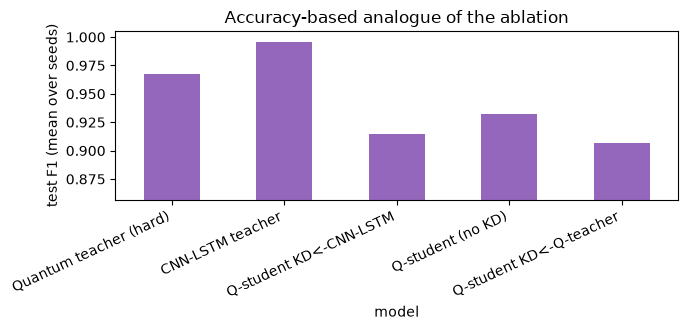

In [22]:
abl = res.loc[["Quantum teacher (hard)", "CNN-LSTM teacher", "Q-student KD<-CNN-LSTM", "Q-student (no KD)", "Q-student KD<-Q-teacher"], ["f1_mean", "accuracy_mean"]].copy()
abl["paper analogue (ARR, Table 3)"] = [82.4, 94.6, 98.1, np.nan, np.nan]
display(abl.round(4))
ax = abl["f1_mean"].plot.bar(figsize=(7, 3.4), color="tab:purple"); ax.set_ylim(max(0, abl["f1_mean"].min() - 0.05), 1.005)
ax.set_ylabel("test F1 (mean over seeds)"); ax.set_title("Accuracy-based analogue of the ablation"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

## 16. Side by side with the paper

Each row is one claim of the paper. Verdict rules: *reproduced* if our number agrees with the claim (within 2 accuracy points or 0.02 F1 where a number is compared; or the stated ordering/direction holds); *not reached* / *exceeded* if it does not, with the gap; *cannot be checked* if it needs something this notebook does not have (DynamicCloudSim, six baseline implementations, packet-level timing).

In [23]:
f1 = res["f1_mean"]; acc = res["accuracy_mean"]
kd_gain = f1["Q-student KD<-Q-teacher"] - f1["Q-student (no KD)"]; kd_gain_cnn = f1["Q-student KD<-CNN-LSTM"] - f1["Q-student (no KD)"]
ag_kd = mim.set_index(["student", "teacher"]).loc[("Q-student KD<-Q-teacher", "Quantum teacher (hard)"), "agreement_mean"]
ag_nokd = mim.set_index(["student", "teacher"]).loc[("Q-student (no KD)", "Quantum teacher (hard)"), "agreement_mean"]
best_base = max([k for k in f1.index if k.startswith(("RandomForest", "SVC"))], key=lambda k: f1[k])
order_ok = (f1["Q-student KD<-CNN-LSTM"] >= f1["CNN-LSTM teacher"] - 0.02) and (f1["Quantum teacher (hard)"] <= f1["CNN-LSTM teacher"] + 0.02)
def verdict(cond, ok="reproduced", bad="not reached"): return ok if cond else bad

comp = pd.DataFrame([
    ["Student mimics teacher 'exactly' (Sec. 4)", "agreement ~ 100%", f"agreement with Q-teacher {ag_kd:.3f} (KD) vs {ag_nokd:.3f} (no KD)", verdict(ag_kd >= 0.98, "reproduced", f"not reached ({ag_kd - 1:+.3f})")],
    ["Distillation helps the quantum student (premise)", "KD student > student without KD", f"dF1 = {kd_gain:+.4f} (from Q-teacher), {kd_gain_cnn:+.4f} (from CNN-LSTM)",
     verdict(max(kd_gain, kd_gain_cnn) > 0.02, "reproduced", "not reached (no gain beyond 0.02 F1)")],
    ["Student is lighter than teacher (Sec. 4, Conclusions)", "fewer qubits/gates/parameters", f"{len(wS)} vs {len(wT)} weights, depth {qc_S.depth()} vs {qc_T.depth()}, {speedup_q:.1f}x faster (simulated)", verdict(len(wS) < len(wT) and speedup_q > 1)],
    ["Ablation ordering (Table 3): CNN-LSTM+Quantum >= CNN-LSTM > Quantum only", "ARR 98.1 > 94.6 > 82.4", f"F1 {f1['Q-student KD<-CNN-LSTM']:.3f} / {f1['CNN-LSTM teacher']:.3f} / {f1['Quantum teacher (hard)']:.3f}", verdict(order_ok, "reproduced (ordering analogue)", "not reached")],
    ["QKD beats classical baselines such as RF (Figs 3-7)", "QKD better on every cloud metric", f"best student F1 {max(f1['Q-student KD<-Q-teacher'], f1['Q-student KD<-CNN-LSTM']):.3f} vs best baseline {best_base} {f1[best_base]:.3f}",
     verdict(max(f1['Q-student KD<-Q-teacher'], f1['Q-student KD<-CNN-LSTM']) >= f1[best_base] - 0.02, "reproduced (detection quality analogue, within 0.02 F1)", "not reached")],
    ["Detection accuracy / F1 of QKD", "not reported", f"test F1 of students {f1['Q-student KD<-CNN-LSTM']:.3f} / {f1['Q-student KD<-Q-teacher']:.3f}", "cannot be checked (no paper value)"],
    ["Packet loss rate 3.9 (Table 2; 20% in Fig 3)", "3.9", "needs DynamicCloudSim", "cannot be checked"],
    ["Attack detection time 118 ms (Table 2; ~40 ms Fig 4)", "118 / 40 ms", f"{eff.loc['Quantum student', 'us per flow']:.0f} us per flow in a numpy simulator (not comparable)", "cannot be checked"],
    ["Attack recovery ratio 95.2 (Table 2; 99% Fig 5)", "95.2 / 99", "needs DynamicCloudSim", "cannot be checked"],
    ["Bandwidth utilisation 88.7 (Table 2; 95% Fig 6)", "88.7 / 95", "needs DynamicCloudSim", "cannot be checked"],
    ["Response time 139 ms (Table 2; 80 ms Fig 7)", "139 / 80 ms", "needs DynamicCloudSim", "cannot be checked"],
], columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 120); display(comp)

,claim,paper,this notebook,verdict
0,Student mimics teacher 'exactly' (Sec. 4),agreement ~ 100%,agreement with Q-teacher 0.905 (KD) vs 0.929 (no KD),not reached (-0.095)
1,Distillation helps the quantum student (premise),KD student > student without KD,"dF1 = -0.0259 (from Q-teacher), -0.0181 (from CNN-LSTM)",not reached (no gain beyond 0.02 F1)
2,"Student is lighter than teacher (Sec. 4, Conclusions)",fewer qubits/gates/parameters,"24 vs 72 weights, depth 15 vs 34, 37.1x faster (simulated)",reproduced
3,Ablation ordering (Table 3): CNN-LSTM+Quantum >= CNN-LSTM > Quantum only,ARR 98.1 > 94.6 > 82.4,F1 0.914 / 0.995 / 0.968,not reached
4,QKD beats classical baselines such as RF (Figs 3-7),QKD better on every cloud metric,best student F1 0.914 vs best baseline RandomForest (8 angles) 0.995,not reached
5,Detection accuracy / F1 of QKD,not reported,test F1 of students 0.914 / 0.907,cannot be checked (no paper value)
6,Packet loss rate 3.9 (Table 2; 20% in Fig 3),3.9,needs DynamicCloudSim,cannot be checked
7,Attack detection time 118 ms (Table 2; ~40 ms Fig 4),118 / 40 ms,130 us per flow in a numpy simulator (not comparable),cannot be checked
8,Attack recovery ratio 95.2 (Table 2; 99% Fig 5),95.2 / 99,needs DynamicCloudSim,cannot be checked
9,Bandwidth utilisation 88.7 (Table 2; 95% Fig 6),88.7 / 95,needs DynamicCloudSim,cannot be checked


## 17. Reading the paper critically

* **No detection accuracy is reported.** The paper's contribution is a *classifier*, yet its evaluation consists only of cloud-simulator curves (packet loss, detection time, recovery, bandwidth, response time). Without accuracy, precision, recall or F1 on the labelled flows, a reader cannot tell whether the QKD model detects attacks any better than a random forest.
* **How is DynamicCloudSim connected to CIC-DDoS2019?** DynamicCloudSim simulates workflows and virtual machines; CIC-DDoS2019 is a recorded packet-flow data set. The paper says features are "extracted using DynamicCloudSim" and sent to Qiskit via REST, but never explains how recorded flows become simulated client tasks. The reported times (40 to 250 ms) also depend on the REST round trip, not on the model.
* **Under-specified model.** "16 to 32 qubits", "6 to 12 layers", and an LSTM with "129 parameters" cannot all be true at once; the CNN input size is 100 while the feature list has seven items; the teacher is a CNN-LSTM in Algorithm 1 and a PQC in the abstract. A 16-qubit teacher trained with parameter-shift gradients on millions of flows is also not feasible on any simulator within the paper's setting.
* **Baseline numbers look hand-set.** The curves quote round values (80%, 50%, 20%) with explanations of *why* each baseline is bad, but no variance, no run count per point, and the same hyper-parameter optimiser is claimed for all methods.
* **Quantum advantage is asserted, not tested.** "Superposition and entanglement" are credited with better performance, but the ablation never replaces the quantum stage with a classical layer of equal size. Section 11 puts a PQC student next to a classical network student of similar input size, and next to a random forest and an SVM; judge the claim from those rows, not from the paper's wording.
* **Most of CIC-DDoS2019 is easy, one family is not.** Reflection attacks (DNS, LDAP, MSSQL, NetBIOS, SSDP, UDP) differ clearly from benign traffic in packet sizes and rates, so tiny models separate them, but in the scatter plots the SYN flows lie on top of the benign flows. The per-family table of Section 11 shows which family the small models miss; an overall accuracy hides that. Differences between methods on the easy families say little about early detection of new attacks.
* **Is distillation doing anything?** Compare the "no KD" and "KD" rows of Sections 11, 12 and 16. When the student already fits the hard labels as well as it can, there is little extra "dark knowledge" to transfer, and the teacher's mistakes can be copied as well. A harder task (unseen attack families, noisy circuits, fewer student qubits) would be a fairer test of distillation.

## 18. Exercises

1. Set `N_S_QUBITS = 2` (and rerun from Section 5). Does distillation help more when the student is weaker? Plot test F1 against student size for the three quantum students.
2. Change `TEMPERATURE` to 1, 3 and 10. How does the agreement between student and teacher (Section 12) change?
3. Change `ALPHA` to 0.1 and 0.9. Which setting follows the teacher more closely, and which follows the labels?
4. Train on the DNS, LDAP and MSSQL families only and test on SYN and UDP. Which models survive an unseen attack family? (Edit the family selection in Section 5.)
5. Replace the CNOT ring by no entanglement (delete the `cx` loop in `build_pqc`). Does the quantum teacher get worse? What does that say about the paper's argument that entanglement captures coordinated attacks?